
Final Results
True reward prob: [0.2, 0.5, 0.75]
Estimated reward prob: [0.21 0.   0.  ]
Number of times each arm was selected: [98.  1.  1.]
Total reward earned: 21


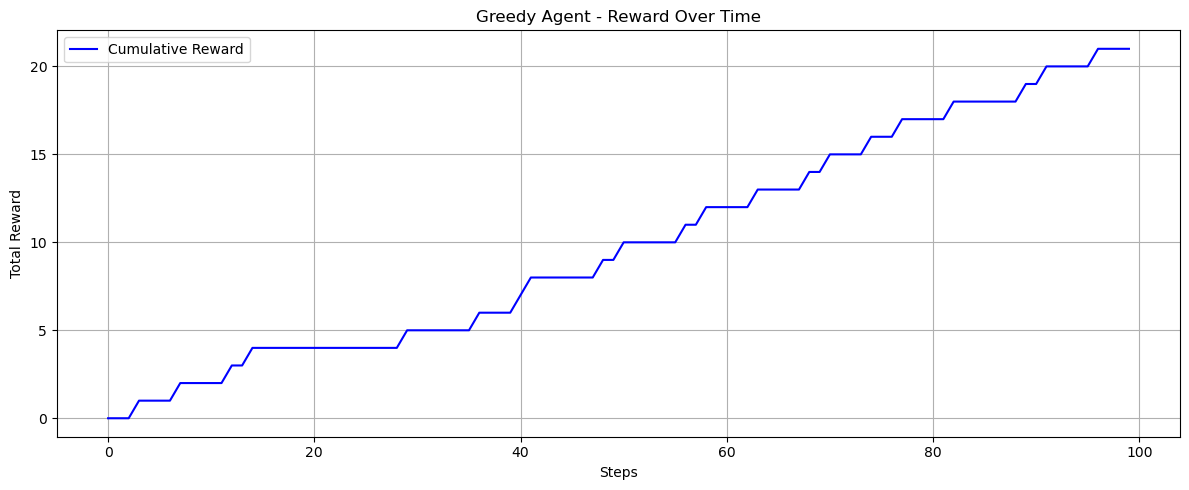

In [5]:
import numpy as np
import matplotlib.pyplot as plt

n_arms = 3
true_rewards = [0.2, 0.5, 0.75]
n_steps = 100

reward_sums = np.zeros(n_arms)
counts = np.zeros(n_arms)
estimated_rewards = np.zeros(n_arms)

reward_history = []
cumulative_reward = []

# --- Initial exploration loop ---
for arm in range(n_arms):
    reward = int(np.random.rand() < true_rewards[arm])
    reward_sums[arm] += reward
    counts[arm] += 1
    estimated_rewards[arm] = reward_sums[arm] / counts[arm]
    reward_history.append(reward)
    
    # FIX 1: Handle the first item safely by checking if the list is empty
    previous_total = cumulative_reward[-1] if cumulative_reward else 0
    cumulative_reward.append(previous_total + reward)

# --- Main exploitation loop ---
for step in range(n_arms, n_steps):
    arm = np.argmax(estimated_rewards)
    reward = int(np.random.rand() < true_rewards[arm])
    
    # FIX 3: Add the actual sampled 'reward' (0 or 1) instead of hardcoding +1
    reward_sums[arm] += reward 
    counts[arm] += 1
    estimated_rewards[arm] = reward_sums[arm] / counts[arm]
    reward_history.append(reward)
    cumulative_reward.append(cumulative_reward[-1] + reward)

print("\nFinal Results")
print("True reward prob:", true_rewards)
# FIX 2: Replaced the dot with a comma to properly format the print function
print("Estimated reward prob:", np.round(estimated_rewards, 2))
print("Number of times each arm was selected:", counts)
print("Total reward earned:", int(sum(reward_history)))

plt.figure(figsize=(12, 5))
# FIX 4: Corrected spelling to match variable initialization
plt.plot(cumulative_reward, label="Cumulative Reward", color='blue')
plt.xlabel("Steps")
plt.ylabel("Total Reward")
plt.title("Greedy Agent - Reward Over Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
